In [ ]:
import sys
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, roc_auc_score, roc_curve

# Preprocess

## Read Data

In [ ]:
PATH = "airline_clnd.csv"
TARGET = "satisfaction"
KOLOM_ID = ["SR", "id"]
TOP_N = 17
JUMLAH_FOLD = 4
BUANG_MANUAL = []
df = pd.read_csv(PATH, sep=";")

In [ ]:
print("Ukuran data:", df.shape)
missing = df.isna().sum()
print(missing[missing > 0] if missing.sum() > 0 else "tidak ada")
df.head()

Ukuran data: (103904, 25)
Arrival_Delay_in_Minutes    310
dtype: int64


,SR,id,Gender,Customer_Type,Age,Type_of_Travel,Class,Flight_Distance,Inflight_wifi_service,Departure/Arrival_time_convenient,...,Inflight_entertainment,On-board_service,Leg_room_service,Baggage_handling,Checkin_service,Inflight_service,Cleanliness,Departure_Delay_in_Minutes,Arrival_Delay_in_Minutes,satisfaction
0,0,70172,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,...,5,4,3,4,4,5,5,25,18.0,neutral or dissatisfied
1,1,5047,Male,disloyal Customer,25,Business travel,Business,235,3,2,...,1,1,5,3,1,4,1,1,6.0,neutral or dissatisfied
2,2,110028,Female,Loyal Customer,26,Business travel,Business,1142,2,2,...,5,4,3,4,4,4,5,0,0.0,satisfied
3,3,24026,Female,Loyal Customer,25,Business travel,Business,562,2,5,...,2,2,5,3,1,4,2,11,9.0,neutral or dissatisfied
4,4,119299,Male,Loyal Customer,61,Business travel,Business,214,3,3,...,3,3,4,4,3,3,3,0,0.0,satisfied


## Encoding

In [ ]:
print("Nilai asli kolom target:")
print(df[TARGET].value_counts(dropna=False))

# Samakan penulisan: hilangkan spasi, huruf kecil
teks = df[TARGET].fillna("").astype(str).str.strip().str.lower()
df["y"] = np.where(teks == "satisfied", 1,
          np.where(teks.str.contains("neutral|dissatisfied|unsatisfied"), -1, np.nan))

# Baris yang targetnya tidak dikenali / kosong dibuang supaya split tidak error
tak_dikenal = df["y"].isna()
print("\nBaris target tidak dikenali/kosong:", int(tak_dikenal.sum()))
if tak_dikenal.any():
    print(df.loc[tak_dikenal, TARGET].value_counts(dropna=False))
df = df.loc[~tak_dikenal].reset_index(drop=True)
df["y"] = df["y"].astype(int)
df["Gender"] = (df["Gender"] == "Male").astype(int)
df["Customer_Type"] = (df["Customer_Type"] == "Loyal Customer").astype(int)
df["Type_of_Travel"] = (df["Type_of_Travel"] == "Business travel").astype(int)
df["Class"] = df["Class"].map({
    "Eco": 1,
    "Eco Plus": 2,
    "Business": 3
})
df[[
    "SR",
    "y",
    "Gender",
    "Customer_Type",
    "Type_of_Travel",
    "Class"
]].head()

Nilai asli kolom target:
satisfaction
neutral or dissatisfied    58879
satisfied                  45025
Name: count, dtype: int64

Baris target tidak dikenali/kosong: 0


,SR,y,Gender,Customer_Type,Type_of_Travel,Class
0,0,-1,1,1,0,2
1,1,-1,1,0,1,3
2,2,1,0,1,1,3
3,3,-1,0,1,1,3
4,4,1,1,1,1,3


## Split 80:20

In [ ]:
TRAIN_PERC = 80
TEST_PERC = 100 - TRAIN_PERC
test_ratio = TEST_PERC / 100

train, test = train_test_split(
    df,
    test_size=test_ratio,
    stratify=df['y'],
    random_state=42
)

train = train.sort_values("SR").reset_index(drop=True)
test = test.sort_values("SR").reset_index(drop=True)

print(f"Rasio split -> Train: {TRAIN_PERC}% | Test: {TEST_PERC}")
print(f"Jumlah Baris  -> Train: {len(train)} | Test: {len(test)}")

print("=== 5 BARIS PERTAMA DATA TRAIN ===")
display(train.head())

print("\n=== 5 BARIS PERTAMA DATA TEST ===")
display(test.head())

Rasio split -> Train: 80% | Test: 20
Jumlah Baris  -> Train: 83123 | Test: 20781
=== 5 BARIS PERTAMA DATA TRAIN ===


,SR,id,Gender,Customer_Type,Age,Type_of_Travel,Class,Flight_Distance,Inflight_wifi_service,Departure/Arrival_time_convenient,...,On-board_service,Leg_room_service,Baggage_handling,Checkin_service,Inflight_service,Cleanliness,Departure_Delay_in_Minutes,Arrival_Delay_in_Minutes,satisfaction,y
0,0,70172,1,1,13,0,2,460,3,4,...,4,3,4,4,5,5,25,18.0,neutral or dissatisfied,-1
1,1,5047,1,0,25,1,3,235,3,2,...,1,5,3,1,4,1,1,6.0,neutral or dissatisfied,-1
2,2,110028,0,1,26,1,3,1142,2,2,...,4,3,4,4,4,5,0,0.0,satisfied,1
3,4,119299,1,1,61,1,3,214,3,3,...,3,4,4,3,3,3,0,0.0,satisfied,1
4,5,111157,0,1,26,0,1,1180,3,4,...,3,4,4,4,4,1,0,0.0,neutral or dissatisfied,-1



=== 5 BARIS PERTAMA DATA TEST ===


,SR,id,Gender,Customer_Type,Age,Type_of_Travel,Class,Flight_Distance,Inflight_wifi_service,Departure/Arrival_time_convenient,...,On-board_service,Leg_room_service,Baggage_handling,Checkin_service,Inflight_service,Cleanliness,Departure_Delay_in_Minutes,Arrival_Delay_in_Minutes,satisfaction,y
0,3,24026,0,1,25,1,3,562,2,5,...,2,5,3,1,4,2,11,9.0,neutral or dissatisfied,-1
1,12,98628,1,1,53,1,1,834,1,4,...,1,1,3,4,4,1,28,8.0,neutral or dissatisfied,-1
2,14,95789,0,1,26,0,1,453,3,2,...,4,3,2,2,1,2,43,35.0,neutral or dissatisfied,-1
3,16,71142,0,1,26,1,3,2123,3,3,...,5,3,4,5,4,4,49,51.0,satisfied,1
4,17,127461,1,1,41,1,3,2075,4,4,...,5,5,5,3,5,5,0,10.0,satisfied,1


### Imputasi Missing Value (Median)
Catatan: missing hanya ada di `Arrival_Delay_in_Minutes`, yang nanti tidak terpilih sebagai fitur model (|r| rendah).

In [ ]:
# Isi missing value dengan median TRAIN (kolom numerik)
kolom_num = df.select_dtypes("number").columns.drop("y", errors="ignore")
median_train = train[kolom_num].median()
train = train.fillna(median_train)
test = test.fillna(median_train)
print("Sisa missing di train:", int(train.isna().sum().sum()), "| test:", int(test.isna().sum().sum()))

Sisa missing di train: 0 | test: 0


# EDA
EDA dilakukan **setelah preprocessing** (encoding, split, imputasi) dan hanya memakai **data train**, supaya data test tidak ikut mempengaruhi pemilihan fitur.

## Balance Check

In [ ]:
jumlah = train["y"].value_counts()
rasio = jumlah.max() / jumlah.min()
print("Jumlah kelas train:", jumlah.to_dict())
print("Rasio mayoritas:minoritas =", round(rasio, 2), "-> seimbang" if rasio <= 1.5 else "-> perlu balancing")

Jumlah kelas train: {-1: 47103, 1: 36020}
Rasio mayoritas:minoritas = 1.31 -> seimbang


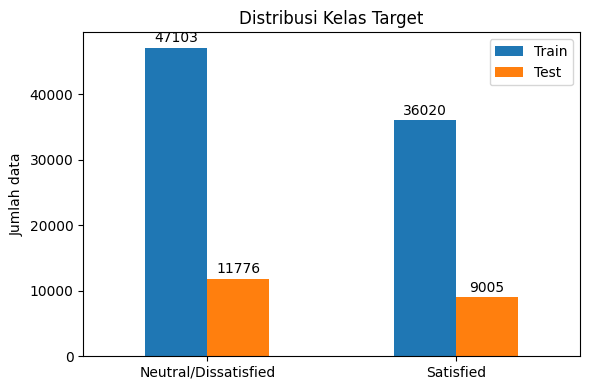

In [ ]:
label = {1: "Satisfied", -1: "Neutral/Dissatisfied"}
tabel_kelas = pd.DataFrame({
    "Train": train["y"].value_counts(),
    "Test": test["y"].value_counts()
}).rename(index=label)

ax = tabel_kelas.plot(kind="bar", figsize=(6, 4), rot=0)
for wadah in ax.containers:
    ax.bar_label(wadah, fmt="%d", padding=2)
ax.set_title("Distribusi Kelas Target")
ax.set_xlabel("")
ax.set_ylabel("Jumlah data")
plt.tight_layout()
plt.show()

## Fungsi Agregat

In [ ]:
fitur = [c for c in df.columns if c not in KOLOM_ID + [TARGET, "y"]]

# 1) Agregat seluruh data train per fitur
agregat = train[fitur].agg(["count", "min", "max", "sum", "mean", "median", "std", "var"]).T
print("Fungsi agregat tiap fitur (data train)")
display(agregat.round(3))

Fungsi agregat tiap fitur (data train)


,count,min,max,sum,mean,median,std,var
Gender,83123.0,0.0,1.0,40958.0,0.493,0.0,0.500,0.250
Customer_Type,83123.0,0.0,1.0,67906.0,0.817,1.0,0.387,0.150
Age,83123.0,7.0,85.0,3274547.0,39.394,40.0,15.128,228.844
Type_of_Travel,83123.0,0.0,1.0,57330.0,0.690,1.0,0.463,0.214
Class,83123.0,1.0,3.0,168634.0,2.029,2.0,0.963,0.927
Flight_Distance,83123.0,31.0,4983.0,98646660.0,1186.755,840.0,995.226,990475.027
Inflight_wifi_service,83123.0,0.0,5.0,227052.0,2.732,3.0,1.327,1.761
Departure/Arrival_time_convenient,83123.0,0.0,5.0,254420.0,3.061,3.0,1.527,2.331
Ease_of_Online_booking,83123.0,0.0,5.0,229258.0,2.758,3.0,1.399,1.956
Gate_location,83123.0,0.0,5.0,247626.0,2.979,3.0,1.277,1.632


### Agregat per kelas target

In [ ]:
# 2) Agregat per kelas target (groupby + agg)
nama_kelas = {1: "Satisfied", -1: "Neutral/Dissatisfied"}

rata_kelas = train.groupby("y")[fitur].agg(["mean", "median", "std"]).rename(index=nama_kelas)
print("Mean, median, dan std tiap fitur per kelas")
display(rata_kelas.T.round(3))

# 3) Ringkasan jumlah data per kelas
ringkas_kelas = train.groupby("y").agg(jumlah=("y", "size"))
ringkas_kelas["persen"] = ringkas_kelas["jumlah"] / ringkas_kelas["jumlah"].sum() * 100
display(ringkas_kelas.rename(index=nama_kelas).round(2))

Mean, median, dan std tiap fitur per kelas


y                                  Neutral/Dissatisfied  Satisfied
Gender                     mean                   0.488      0.499
                           median                 0.000      0.000
                           std                    0.500      0.500
Customer_Type              mean                   0.753      0.900
                           median                 1.000      1.000
...                                                 ...        ...
Departure_Delay_in_Minutes median                 0.000      0.000
                           std                   40.264     35.886
Arrival_Delay_in_Minutes   mean                  17.129     12.713
                           median                 0.000      0.000
                           std                   40.548     36.441

[66 rows x 2 columns]

,jumlah,persen
y,,
Neutral/Dissatisfied,47103,56.67
Satisfied,36020,43.33


## Distribusi Fitur
Histogram tiap fitur pada data train, untuk melihat sebaran dan kemiringan data.

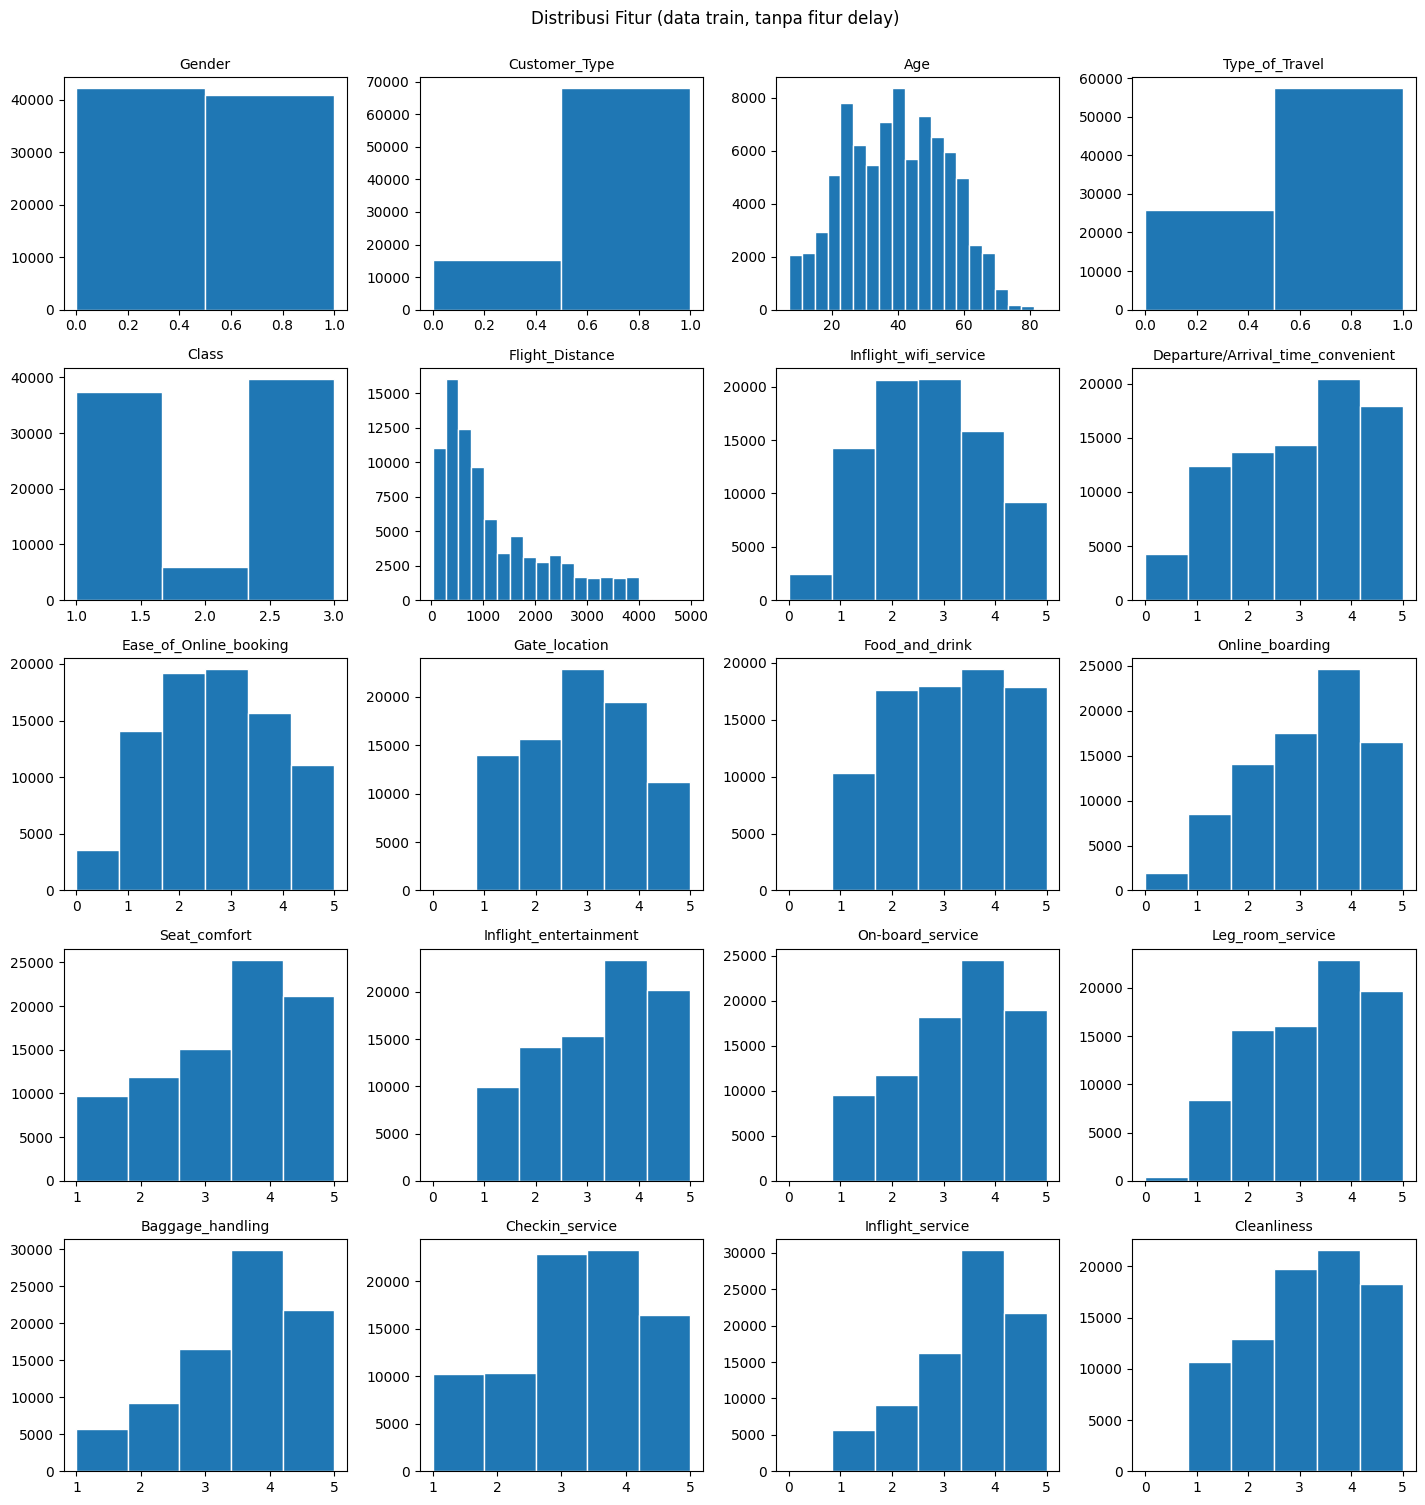

In [ ]:
DELAY = ["Departure_Delay_in_Minutes", "Arrival_Delay_in_Minutes"]

# Data train versi lengkap (semua kolom), tidak terpengaruh train.csv yang di-load ulang
data_eda = df[df["SR"].isin(train["SR"])]
fitur_eda = [c for c in df.columns if c not in KOLOM_ID + [TARGET, "y"] + DELAY]

def kisi(n, kolom=4, lebar=3.6, tinggi=3.0):
    baris = int(np.ceil(n / kolom))
    fig, axes = plt.subplots(baris, kolom, figsize=(lebar * kolom, tinggi * baris))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes[n:]:
        ax.axis("off")
    return fig, axes

fig, axes = kisi(len(fitur_eda))
for ax, f in zip(axes, fitur_eda):
    ax.hist(data_eda[f], bins=min(20, data_eda[f].nunique()), color="tab:blue", edgecolor="white")
    ax.set_title(f, fontsize=10)
fig.suptitle("Distribusi Fitur (data train, tanpa fitur delay)", y=1.0)
plt.tight_layout(); plt.show()

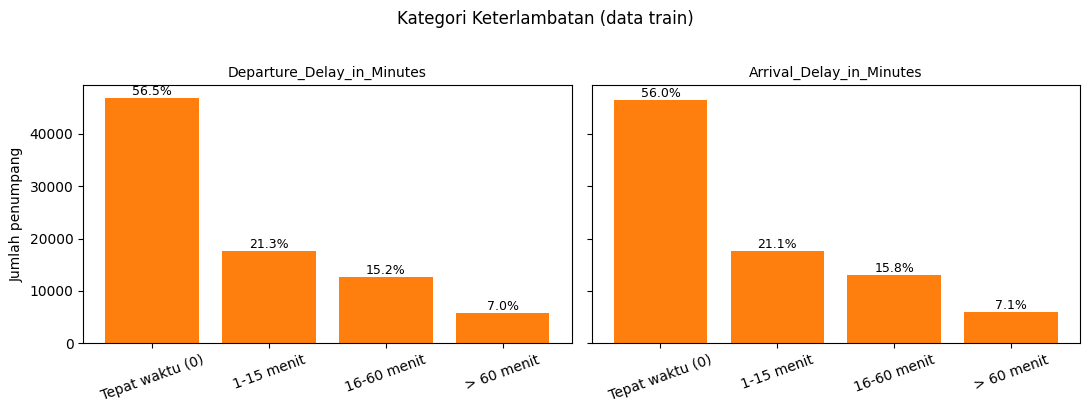

In [ ]:
batas = [-1, 0, 15, 60, np.inf]
label_delay = ["Tepat waktu (0)", "1-15 menit", "16-60 menit", "> 60 menit"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, f in zip(axes, DELAY):
    kat = pd.cut(data_eda[f], bins=batas, labels=label_delay)
    jumlah = kat.value_counts().reindex(label_delay)
    ax.bar(jumlah.index, jumlah.values, color="tab:orange")
    for i, v in enumerate(jumlah.values):
        ax.text(i, v, f"{v / jumlah.sum():.1%}", ha="center", va="bottom", fontsize=9)
    ax.set_title(f, fontsize=10)
    ax.tick_params(axis="x", rotation=20)
axes[0].set_ylabel("Jumlah penumpang")
fig.suptitle("Kategori Keterlambatan (data train)", y=1.02)
plt.tight_layout(); plt.show()

## Boxplot per Kelas dan Outlier
Fitur kontinu (lebih dari 10 nilai unik) dibandingkan antar kelas target.

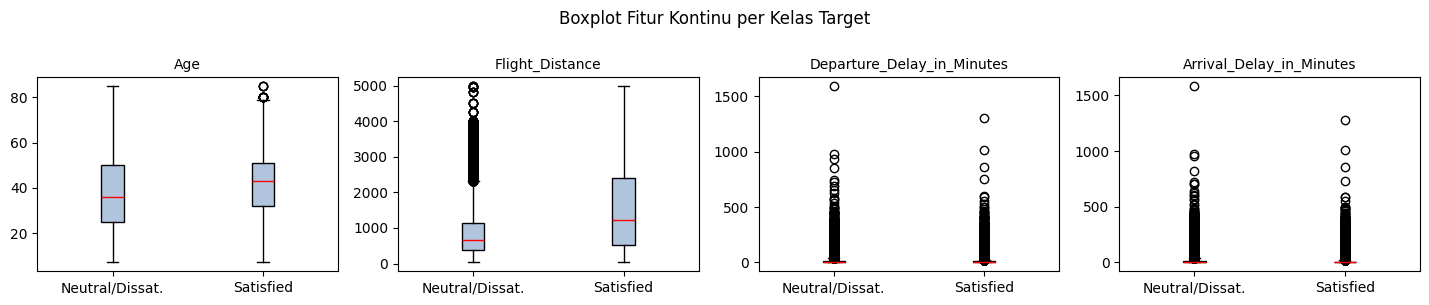

,jumlah outlier,persen
Age,0,0.00
Flight_Distance,1886,2.27
Departure_Delay_in_Minutes,11604,13.96
Arrival_Delay_in_Minutes,11193,13.47


In [ ]:
kontinu = [f for f in fitur if train[f].nunique() > 10]
fig, axes = kisi(len(kontinu), kolom=min(4, len(kontinu)))
for ax, f in zip(axes, kontinu):
    data = [train.loc[train["y"] == k, f] for k in (-1, 1)]
    ax.boxplot(data, tick_labels=["Neutral/Dissat.", "Satisfied"], patch_artist=True,
               boxprops=dict(facecolor="lightsteelblue"), medianprops=dict(color="red"))
    ax.set_title(f, fontsize=10)
fig.suptitle("Boxplot Fitur Kontinu per Kelas Target", y=1.0)
plt.tight_layout()
plt.show()

# Jumlah outlier (aturan IQR 1,5) tiap fitur kontinu
q1, q3 = train[kontinu].quantile(0.25), train[kontinu].quantile(0.75)
iqr = q3 - q1
outlier = ((train[kontinu] < q1 - 1.5 * iqr) | (train[kontinu] > q3 + 1.5 * iqr)).sum()
display(pd.DataFrame({"jumlah outlier": outlier, "persen": (outlier / len(train) * 100).round(2)}))

## Fitur Diskrit vs Target
Fitur dengan 10 nilai unik atau kurang (biner, kelas, rating): jumlah penumpang tiap nilai, dipisah menurut kepuasan.

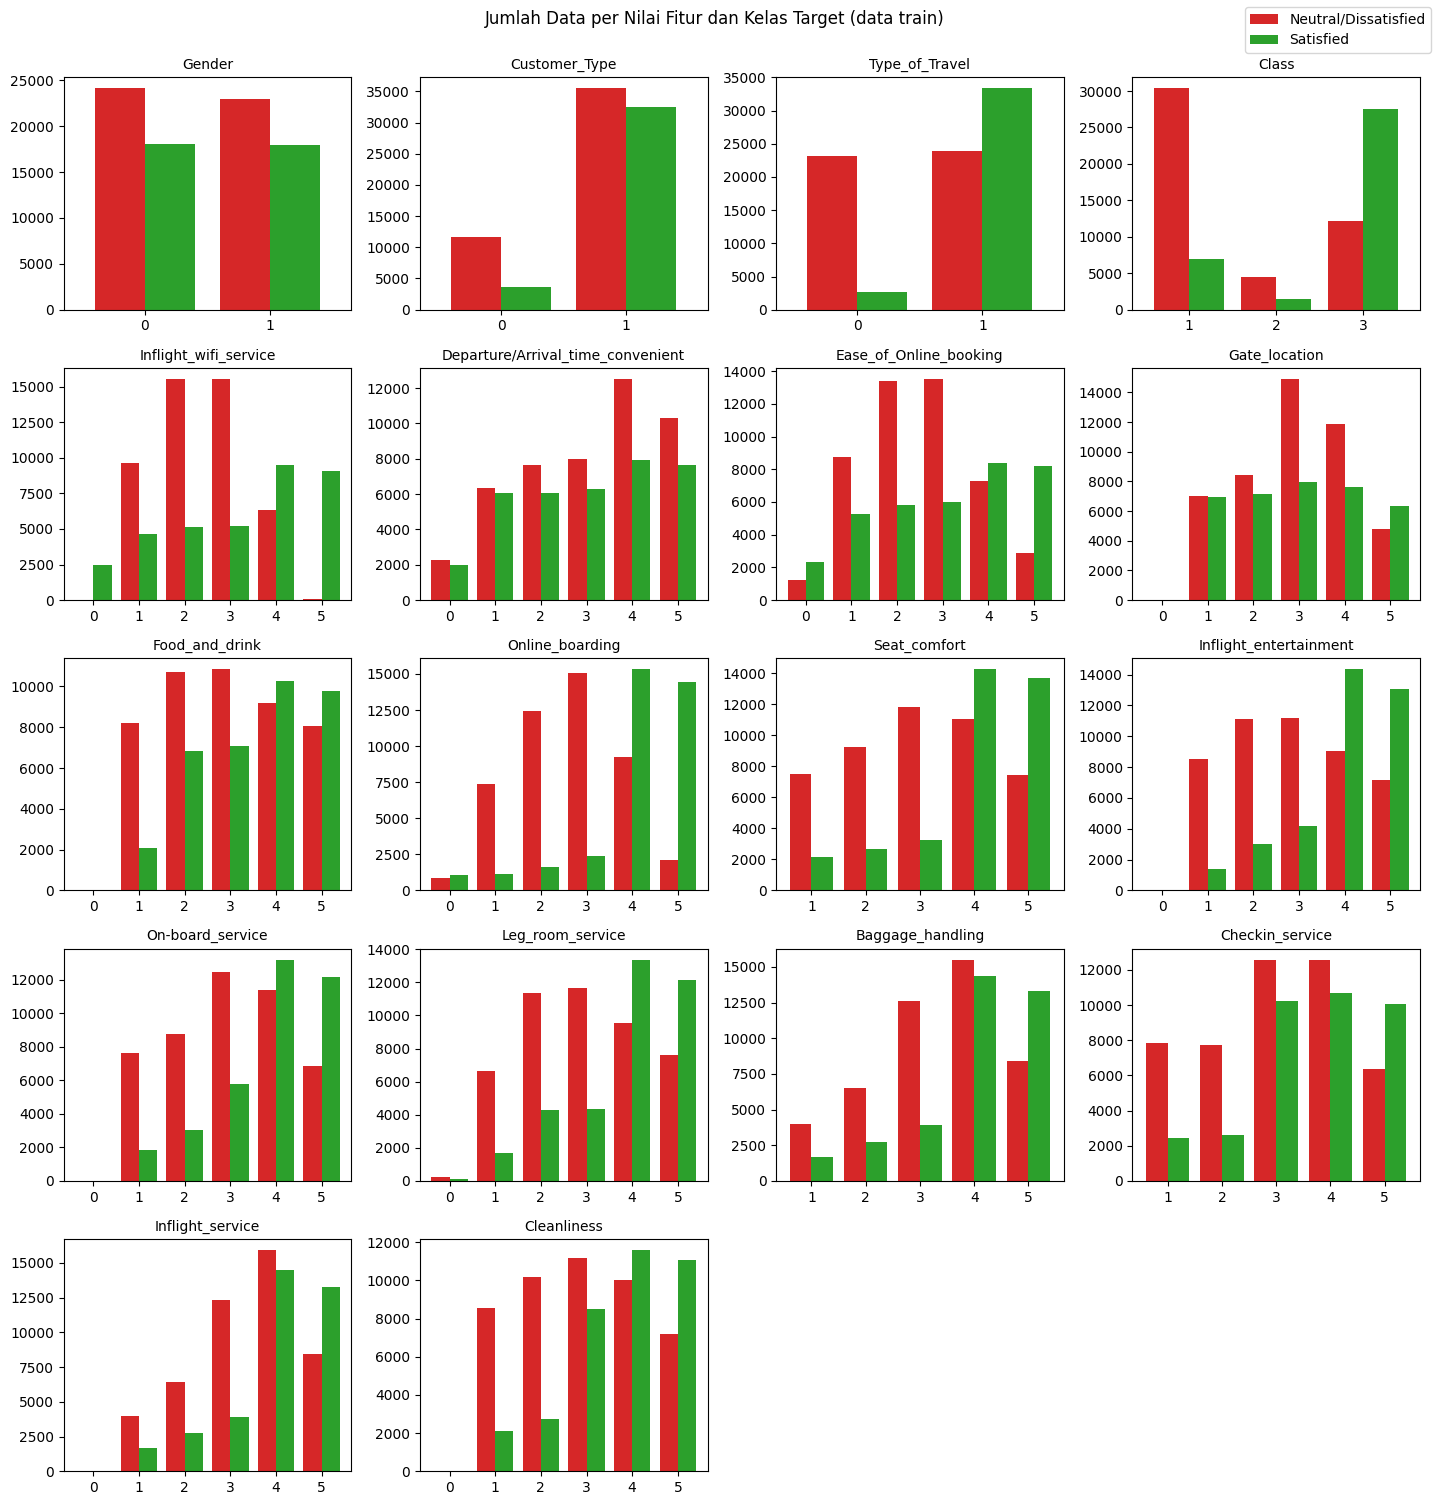

In [ ]:
def kisi(n, kolom=4, lebar=3.6, tinggi=3.0):
    baris = int(np.ceil(n / kolom))
    fig, axes = plt.subplots(baris, kolom, figsize=(lebar * kolom, tinggi * baris))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes[n:]:
        ax.axis("off")
    return fig, axes

diskrit = [f for f in fitur if train[f].nunique() <= 10]
fig, axes = kisi(len(diskrit))
for ax, f in zip(axes, diskrit):
    ct = pd.crosstab(train[f], train["y"]).rename(columns=nama_kelas)
    ct.plot(kind="bar", ax=ax, rot=0, width=0.8, color=["tab:red", "tab:green"], legend=False)
    ax.set_title(f, fontsize=10)
    ax.set_xlabel("")
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="upper right")
fig.suptitle("Jumlah Data per Nilai Fitur dan Kelas Target (data train)", y=1.0)
plt.tight_layout()
plt.show()

## Perbandingan Rata-rata Fitur per Kelas
Rata-rata fitur yang sudah distandarkan (z-score) pada tiap kelas, supaya fitur berskala berbeda bisa dibandingkan.

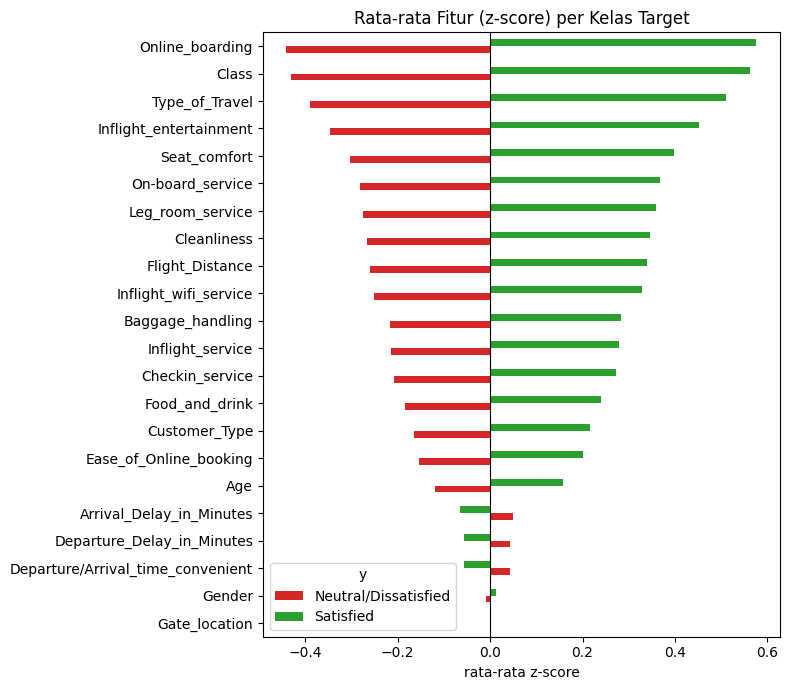

In [ ]:
z = (train[fitur] - train[fitur].mean()) / train[fitur].std()
selisih = z.groupby(train["y"]).mean().T.rename(columns=nama_kelas)
selisih = selisih.loc[(selisih["Satisfied"] - selisih["Neutral/Dissatisfied"]).abs().sort_values().index]
selisih.plot(kind="barh", figsize=(8, 7), color=["tab:red", "tab:green"])
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Rata-rata Fitur (z-score) per Kelas Target")
plt.xlabel("rata-rata z-score")
plt.tight_layout()
plt.show()

## Tabel Korelasi Antar Fitur

,Gender,Customer_Type,Age,Type_of_Travel,Class,Flight_Distance,Inflight_wifi_service,Departure/Arrival_time_convenient,Ease_of_Online_booking,Gate_location,Food_and_drink,Online_boarding,Seat_comfort,Inflight_entertainment,On-board_service,Leg_room_service,Baggage_handling,Checkin_service,Inflight_service,Cleanliness,Departure_Delay_in_Minutes,Arrival_Delay_in_Minutes,y
Gender,1.00,0.03,0.01,-0.01,0.01,0.00,0.01,0.01,0.01,0.00,0.01,-0.04,-0.03,0.01,0.01,0.03,0.04,0.01,0.04,0.01,0.00,-0.00,0.01
Customer_Type,0.03,1.00,0.28,-0.31,0.10,0.22,0.01,0.21,0.02,-0.01,0.06,0.19,0.16,0.11,0.06,0.05,-0.03,0.03,-0.02,0.08,-0.00,-0.00,0.19
Age,0.01,0.28,1.00,0.05,0.14,0.10,0.02,0.04,0.03,0.00,0.02,0.21,0.16,0.08,0.06,0.04,-0.05,0.04,-0.05,0.06,-0.01,-0.01,0.14
Type_of_Travel,-0.01,-0.31,0.05,1.00,0.54,0.27,0.11,-0.26,0.13,0.03,0.06,0.22,0.12,0.15,0.05,0.14,0.03,-0.02,0.02,0.08,0.00,0.00,0.45
Class,0.01,0.10,0.14,0.54,1.00,0.45,0.04,-0.09,0.11,0.00,0.08,0.32,0.22,0.19,0.21,0.20,0.16,0.15,0.15,0.13,-0.01,-0.01,0.49
Flight_Distance,0.00,0.22,0.10,0.27,0.45,1.00,0.01,-0.02,0.07,0.01,0.05,0.21,0.15,0.13,0.11,0.13,0.06,0.07,0.06,0.09,0.00,-0.00,0.30
Inflight_wifi_service,0.01,0.01,0.02,0.11,0.04,0.01,1.00,0.34,0.72,0.34,0.13,0.46,0.12,0.21,0.12,0.16,0.12,0.04,0.11,0.13,-0.02,-0.02,0.29
Departure/Arrival_time_convenient,0.01,0.21,0.04,-0.26,-0.09,-0.02,0.34,1.00,0.44,0.44,0.00,0.07,0.01,-0.00,0.07,0.02,0.08,0.09,0.07,0.02,-0.00,-0.00,-0.05
Ease_of_Online_booking,0.01,0.02,0.03,0.13,0.11,0.07,0.72,0.44,1.00,0.46,0.03,0.41,0.03,0.05,0.04,0.11,0.04,0.01,0.04,0.02,-0.01,-0.01,0.17
Gate_location,0.00,-0.01,0.00,0.03,0.00,0.01,0.34,0.44,0.46,1.00,-0.00,0.00,0.00,0.01,-0.03,-0.01,0.00,-0.03,0.00,-0.00,0.00,0.00,0.00


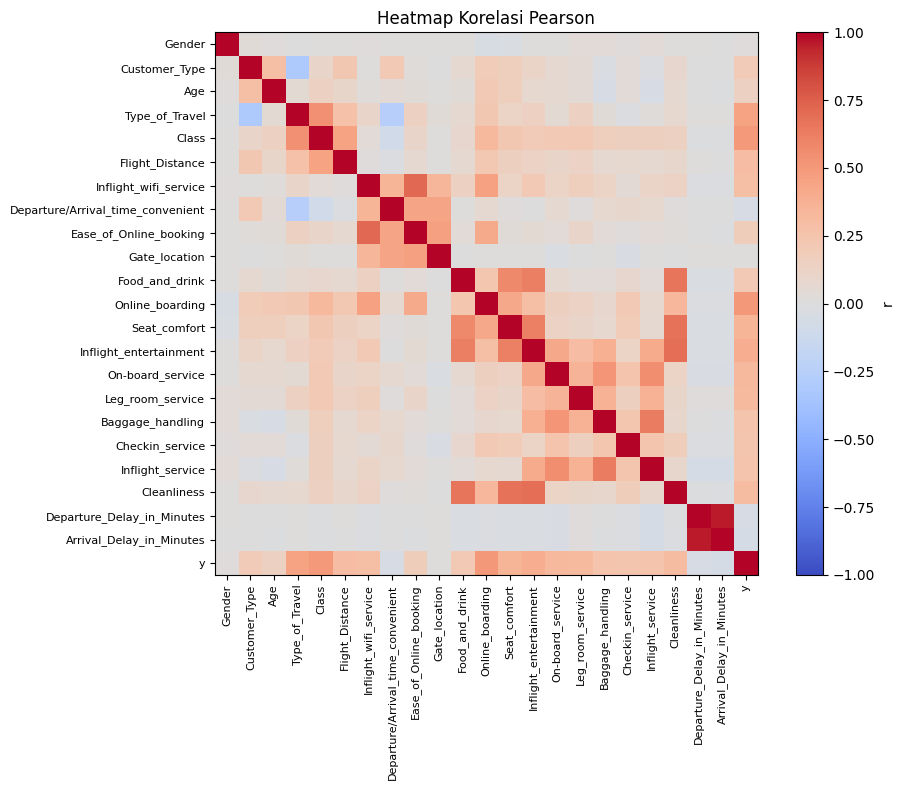

In [ ]:
# Matriks korelasi Pearson seluruh fitur + target (data train)
tabel_korelasi = train[fitur + ["y"]].corr()
display(tabel_korelasi.round(2).style.background_gradient(cmap="coolwarm", vmin=-1, vmax=1).format("{:.2f}"))

plt.figure(figsize=(10, 8))
plt.imshow(tabel_korelasi, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="r")
plt.xticks(range(len(tabel_korelasi)), tabel_korelasi.columns, rotation=90, fontsize=8)
plt.yticks(range(len(tabel_korelasi)), tabel_korelasi.index, fontsize=8)
plt.title("Heatmap Korelasi Pearson")
plt.tight_layout()
plt.show()

### Pasangan fitur berkorelasi tinggi
Pasangan dengan |r| ≥ 0,7 menandakan fitur yang saling tumpang tindih (redundan).

In [ ]:
BATAS_KORELASI = 0.7
pasangan = (tabel_korelasi.drop(index="y", columns="y")
            .where(np.triu(np.ones((len(fitur), len(fitur))), k=1).astype(bool))
            .stack()
            .rename("r").reset_index()
            .rename(columns={"level_0": "Fitur A", "level_1": "Fitur B"}))
pasangan = pasangan[pasangan["r"].abs() >= BATAS_KORELASI].sort_values("r", key=abs, ascending=False)
display(pasangan.round(3).reset_index(drop=True) if len(pasangan) else "Tidak ada pasangan fitur dengan |r| >= 0,7")

,Fitur A,Fitur B,r
0,Departure_Delay_in_Minutes,Arrival_Delay_in_Minutes,0.960
1,Inflight_wifi_service,Ease_of_Online_booking,0.717


## Korelasi fitur target

In [ ]:
fitur = [c for c in df.columns if c not in KOLOM_ID + [TARGET, "y"]]
r = train[fitur].corrwith(train["y"])
tabel = pd.DataFrame({"r": r, "abs_r": r.abs()})
tabel["dipakai"] = ~tabel.index.isin(BUANG_MANUAL)
tabel["peringkat"] = tabel["abs_r"].where(tabel["dipakai"]).rank(ascending=False)
tabel.sort_values("abs_r", ascending=False).round(4)

,r,abs_r,dipakai,peringkat
Online_boarding,0.5040,0.5040,True,1.0
Class,0.4923,0.4923,True,2.0
Type_of_Travel,0.4463,0.4463,True,3.0
Inflight_entertainment,0.3959,0.3959,True,4.0
Seat_comfort,0.3474,0.3474,True,5.0
On-board_service,0.3212,0.3212,True,6.0
Leg_room_service,0.3145,0.3145,True,7.0
Cleanliness,0.3033,0.3033,True,8.0
Flight_Distance,0.2967,0.2967,True,9.0
Inflight_wifi_service,0.2867,0.2867,True,10.0


In [ ]:
tabel.round(6).to_csv("korelasi.csv")

### Fitur terpilih

In [ ]:
fitur_terpilih = (tabel[tabel["dipakai"]].sort_values("abs_r", ascending=False).head(TOP_N).index.tolist())
fitur_terpilih

['Online_boarding',
 'Class',
 'Type_of_Travel',
 'Inflight_entertainment',
 'Seat_comfort',
 'On-board_service',
 'Leg_room_service',
 'Cleanliness',
 'Flight_Distance',
 'Inflight_wifi_service',
 'Baggage_handling',
 'Inflight_service',
 'Checkin_service',
 'Food_and_drink',
 'Customer_Type',
 'Ease_of_Online_booking',
 'Age']

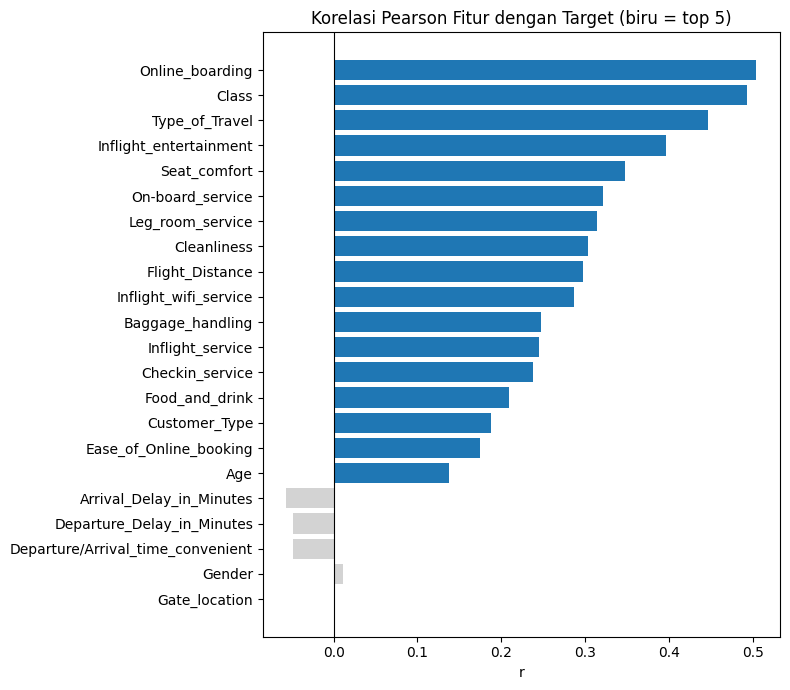

In [ ]:
urut = tabel.sort_values("abs_r")
warna = ["tab:blue" if f in fitur_terpilih else "lightgray" for f in urut.index]

plt.figure(figsize=(8, 7))
plt.barh(urut.index, urut["r"], color=warna)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Korelasi Pearson Fitur dengan Target (biru = terpilih)")
plt.xlabel("r")
plt.tight_layout()
plt.show()

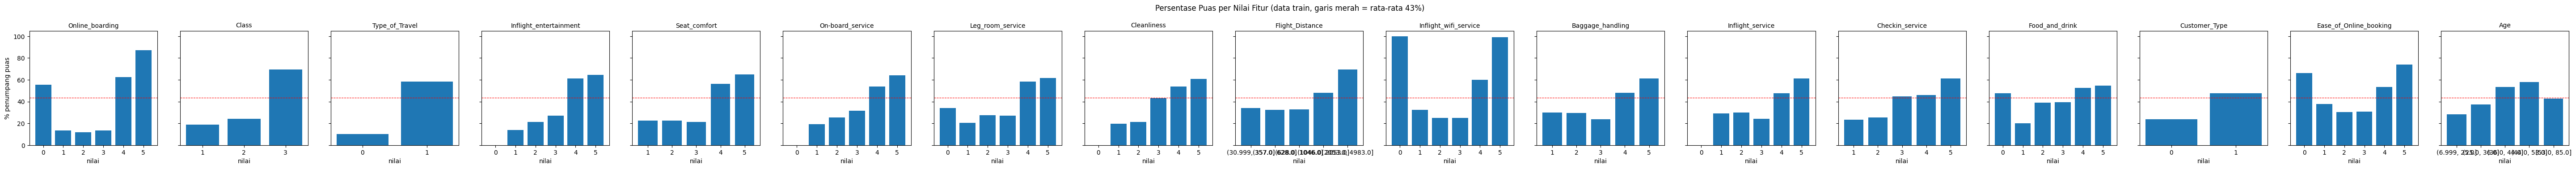

In [ ]:
rata_puas = (train["y"] == 1).mean() * 100

fig, axes = plt.subplots(1, len(fitur_terpilih), figsize=(3.4 * len(fitur_terpilih), 3.8), sharey=True)
for ax, f in zip(axes, fitur_terpilih):
    kolom = train[f]
    if kolom.nunique() > 10:                 # fitur kontinu: dibagi jadi 5 kelompok
        kolom = pd.qcut(kolom, 5, duplicates="drop")
    persen = train.groupby(kolom, observed=True)["y"].apply(lambda s: (s == 1).mean() * 100)
    ax.bar(persen.index.astype(str), persen.values)
    ax.axhline(rata_puas, color="red", linestyle="--", linewidth=0.8)
    ax.set_title(f, fontsize=10)
    ax.set_xlabel("nilai")
axes[0].set_ylabel("% penumpang puas")
fig.suptitle(f"Persentase Puas per Nilai Fitur (data train, garis merah = rata-rata {rata_puas:.0f}%)")
plt.tight_layout()
plt.show()

# Finalisasi Data untuk Modelling
Setelah fitur terpilih lewat EDA, data train diberi nomor fold lalu disimpan.

## Nomor Fold untuk Cross Validation (Train)

In [ ]:
train["fold"] = train.index % JUMLAH_FOLD + 1
train[[
    "SR",
    "y"
] + fitur_terpilih + ["fold"]]

,SR,y,Online_boarding,Class,Type_of_Travel,Inflight_entertainment,Seat_comfort,On-board_service,Leg_room_service,Cleanliness,Flight_Distance,Inflight_wifi_service,Baggage_handling,Inflight_service,Checkin_service,Food_and_drink,Customer_Type,Ease_of_Online_booking,Age,fold
0,0,-1,3,2,0,5,5,4,3,5,460,3,4,5,4,5,1,3,13,1
1,1,-1,3,3,1,1,1,1,5,1,235,3,3,4,1,1,0,3,25,2
2,2,1,5,3,1,5,5,4,3,5,1142,2,4,4,4,5,1,2,26,3
3,4,1,5,3,1,3,5,3,4,3,214,3,4,3,3,4,1,3,61,4
4,5,-1,2,1,0,1,1,3,4,1,1180,3,4,4,4,1,1,2,26,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
83118,103898,-1,3,1,0,2,2,4,3,2,1620,3,4,4,2,2,1,3,50,3
83119,103900,1,4,3,1,5,5,5,5,4,2347,4,5,5,5,2,1,4,49,4
83120,103901,-1,1,3,1,4,5,3,2,4,1995,1,4,5,5,4,0,1,30,1
83121,103902,-1,1,1,1,1,1,4,5,1,1000,1,1,4,5,1,0,1,22,2


### Simpan data siap pakai

In [ ]:
kolom_simpan = ["SR", "y"] + fitur_terpilih
train[kolom_simpan + ["fold"]].to_csv("train.csv", index=False)
test[kolom_simpan].to_csv("test.csv", index=False)
test[kolom_simpan]

,SR,y,Online_boarding,Class,Type_of_Travel,Inflight_entertainment,Seat_comfort,On-board_service,Leg_room_service,Cleanliness,Flight_Distance,Inflight_wifi_service,Baggage_handling,Inflight_service,Checkin_service,Food_and_drink,Customer_Type,Ease_of_Online_booking,Age
0,3,-1,2,3,1,2,2,2,5,2,562,2,3,4,1,2,1,5,25
1,12,-1,1,1,1,1,1,1,1,1,834,1,3,4,4,1,1,4,53
2,14,-1,3,1,0,2,2,4,3,2,453,3,2,1,2,2,1,3,26
3,16,1,4,3,1,4,4,5,3,4,2123,3,4,4,5,4,1,3,26
4,17,1,4,3,1,5,4,5,5,5,2075,4,5,5,3,4,1,2,41
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20776,103879,1,4,3,1,4,4,3,4,4,2338,1,4,5,5,4,1,1,30
20777,103881,1,5,3,1,4,5,4,4,3,384,2,4,4,3,5,1,2,51
20778,103889,1,5,3,1,3,5,3,3,3,3885,5,3,3,4,4,1,5,43
20779,103897,1,5,3,1,4,4,4,4,4,1599,5,4,4,4,5,1,5,60


# Modelling

## Data Train

In [ ]:
train = pd.read_csv("train.csv")

fitur = [c for c in train.columns if c not in ["SR", "y", "fold"]]
x = train[fitur].to_numpy()
y = train["y"].to_numpy()

print(f"Fitur: {fitur}")
print(f"Jumlah data train: {len(y)}")

Fitur: ['Online_boarding', 'Class', 'Type_of_Travel', 'Inflight_entertainment', 'Seat_comfort', 'On-board_service', 'Leg_room_service', 'Cleanliness', 'Flight_Distance', 'Inflight_wifi_service', 'Baggage_handling', 'Inflight_service', 'Checkin_service', 'Food_and_drink', 'Customer_Type', 'Ease_of_Online_booking', 'Age']
Jumlah data train: 83123


## Settings

In [ ]:
T = 67            # iterasi
EPS_MIN = 0.0001 # mencegah α menjadi tak hingga jika stump (error) sempurna

## Decision Stump

In [ ]:
def tebak_stump(x, stump):
  """Tebak h(x) +1 or -1"""
  dasar = np.where(x[:, stump["j"]] > stump["thr"], 1, -1)
  return stump["pol"] * dasar

def cari_stump_terbaik(x, y, w):
  """Hitung semua fitur dan threshold serta mengambil bobot terbaik (paling kecil)"""
  terbaik = None
  for j in range(x.shape[1]):
    nilai = np.unique(x[:, j])
    kandidat = (nilai[:-1] + nilai[1:])  / 2
    for thr in kandidat:
      tebakan = np.where(x[:,j] > thr, 1, -1)
      eps = w[tebakan != y].sum()
      pol = 1
      if eps > 0.5:
        eps, pol = 1 - eps, -1
      if terbaik is None or eps < terbaik["eps"]:
        terbaik = {
            "j": j,
            "fitur": fitur[j],
            "thr": thr,
            "pol": pol,
            "eps": eps
        }
  return terbaik

## AdaBoost
Tiap iterasi:
1. Cari stump terbaik memakai bobot data saat ini.
2. Hitung bobot suara stump: **α = ½ · ln((1 - ε) / ε)**.
3. Update bobot data: `w · e^(-α · y · h)`. Salah tebak naik, benar tebak turun.
4. Normalisasi bobot supaya totalnya 1.

In [ ]:
GRID_THR = [0.5, 1.5, 2.5, 3.5, 4.5]   # sama dengan tabel di Excel
LABEL_THR = [f"{g:g}" for g in GRID_THR]

def tabel_error(x, y, w):
    """Tabel error tiap fitur x threshold (kiri) dan ε min (kanan), seperti di Excel."""
    kiri = pd.DataFrame(np.nan, index=fitur, columns=LABEL_THR)
    for j, f in enumerate(fitur):
        for thr, label in zip(GRID_THR, LABEL_THR):
            tebakan = np.where(x[:, j] > thr, 1, -1)
            if len(np.unique(tebakan)) == 1:      # threshold tidak memisahkan data, dilewati
                continue
            kiri.loc[f, label] = w[tebakan != y].sum()
    kanan = np.minimum(kiri, 1 - kiri)
    tabel = pd.concat({
        'Error ε jika "x > threshold --> satisfied"': kiri,
        "ε min = min(ε, 1-ε)": kanan,
    }, axis=1)
    tabel[("", "ε terkecil")] = kanan.min(axis=1)
    tabel.index.name = "Fitur"
    return tabel


def tabel_terpilih(stump, eps, alpha):
    """Tabel stump terpilih, seperti di Excel."""
    tanda = ">" if stump["pol"] == 1 else "≤"
    idx_thr = GRID_THR.index(stump["thr"]) + 1 if stump["thr"] in GRID_THR else "-"
    return pd.DataFrame([{
        "Stump Terpilih": stump["fitur"],
        "Threshold": stump["thr"],
        "Polaritas": stump["pol"],
        "ε": round(eps, 4),
        "α = ½·ln((1-ε)/ε)": round(alpha, 4),
        "Aturan": f"Jika {stump['fitur']} {tanda} {stump['thr']:g} --> satisfied, selain itu neutral/dissatisfied",
        "idx fitur": stump["j"] + 1,
        "idx thr": idx_thr,
    }])

In [ ]:
N = len(y)
w = np.full(N, 1 / N)
model = []

for t in range(1, T + 1):
    stump = cari_stump_terbaik(x, y, w)
    eps = max(stump["eps"], EPS_MIN)
    alpha = 0.5 * np.log((1 - eps) / eps)
    h = tebak_stump(x, stump)

    print(f"===== Iterasi {t} =====")
    display(tabel_error(x, y, w).style.format(lambda v: f"{v + 1e-12:.3f}", na_rep="-"))
    display(tabel_terpilih(stump, eps, alpha).style.hide(axis="index"))

    salah = h != y
    w = w * np.exp(-alpha * y * h)
    w = w / w.sum()

    stump["alpha"] = alpha
    stump["iterasi"] = t
    model.append(stump)
    print(f"Data salah: {int(salah.sum())} dari {N} | bobot terbesar sesudah update = {w.max():.8f}\n")

===== Iterasi 1 =====


Stump Terpilih,Threshold,Polaritas,ε,α = ½·ln((1-ε)/ε),Aturan,idx fitur,idx thr
Online_boarding,3.500000,1,0.212300,0.655500,"Jika Online_boarding > 3.5 --> satisfied, selain itu neutral/dissatisfied",1,4


Data salah: 17648 dari 83123 | bobot terbesar sesudah update = 0.00002833

===== Iterasi 2 =====


Stump Terpilih,Threshold,Polaritas,ε,α = ½·ln((1-ε)/ε),Aturan,idx fitur,idx thr
Class,2.500000,1,0.269900,0.497600,"Jika Class > 2.5 --> satisfied, selain itu neutral/dissatisfied",2,3


Data salah: 20653 dari 83123 | bobot terbesar sesudah update = 0.00005249

===== Iterasi 3 =====


Stump Terpilih,Threshold,Polaritas,ε,α = ½·ln((1-ε)/ε),Aturan,idx fitur,idx thr
Inflight_wifi_service,4.500000,1,0.303500,0.415200,"Jika Inflight_wifi_service > 4.5 --> satisfied, selain itu neutral/dissatisfied",10,5


... (125 outputs left out)

Stump Terpilih,Threshold,Polaritas,ε,α = ½·ln((1-ε)/ε),Aturan,idx fitur,idx thr
Seat_comfort,4.500000,1,0.478700,0.042700,"Jika Seat_comfort > 4.5 --> satisfied, selain itu neutral/dissatisfied",5,5


Data salah: 29778 dari 83123 | bobot terbesar sesudah update = 0.00083257

===== Iterasi 67 =====


Stump Terpilih,Threshold,Polaritas,ε,α = ½·ln((1-ε)/ε),Aturan,idx fitur,idx thr
Type_of_Travel,0.500000,1,0.475400,0.049200,"Jika Type_of_Travel > 0.5 --> satisfied, selain itu neutral/dissatisfied",3,1


Data salah: 26654 dari 83123 | bobot terbesar sesudah update = 0.00087559



## Final Model

In [ ]:
tabel_model = pd.DataFrame(model)[[
    "iterasi",
    "fitur",
    "thr",
    "pol",
    "eps",
    "alpha"
]]
tabel_model.round(4)

,iterasi,fitur,thr,pol,eps,alpha
0,1,Online_boarding,3.5,1,0.2123,0.6555
1,2,Class,2.5,1,0.2699,0.4976
2,3,Inflight_wifi_service,4.5,1,0.3035,0.4152
3,4,Leg_room_service,3.5,1,0.3382,0.3356
4,5,Type_of_Travel,0.5,1,0.3450,0.3205
...,...,...,...,...,...,...
62,63,Inflight_entertainment,0.5,1,0.4722,0.0557
63,64,Age,24.5,-1,0.4725,0.0551
64,65,On-board_service,2.5,1,0.4783,0.0434
65,66,Seat_comfort,4.5,1,0.4787,0.0427


## Ensemble Prediction
**H(x) = Σ αₜ·hₜ(x), t = 1 sampai T**. Prediksi puas (+1) jika H > 0, selain itu tidak puas (-1).

In [ ]:
def prediksi(x, model):
  H = np.zeros(len(x))
  for s in model:
    H += s["alpha"] * tebak_stump(x, s)
  return H, np.where(H > 0, 1, -1)

H, pred = prediksi(x, model)
akurasi_train = (pred==y).mean()
print(f"Akurasi data train: {akurasi_train:.2%}")

hasil = train.copy()
hasil["H(x)"] = H.round(4)
hasil["prediksi"] = pred
hasil["hasil"] = np.where(pred == y, "Benar", "Salah")
hasil[
    (["SR"] if "SR" in hasil.columns else []) + ["y", "H(x)", "prediksi", "hasil"]
]

Akurasi data train: 92.16%


,SR,y,H(x),prediksi,hasil
0,0,-1,-2.3310,-1,Benar
1,1,-1,-2.4813,-1,Benar
2,2,1,1.2783,1,Benar
3,4,1,1.1410,1,Benar
4,5,-1,-2.5583,-1,Benar
...,...,...,...,...,...
83118,103898,-1,-2.9904,-1,Benar
83119,103900,1,2.7815,1,Benar
83120,103901,-1,-1.1094,-1,Benar
83121,103902,-1,-1.8436,-1,Benar


## Simpan Model


In [ ]:
tabel_model.to_csv("model_adaboost.csv", index=False)
print("Tersimpan: model_adaboost.csv")

Tersimpan: model_adaboost.csv


# Tuning Hyperparameter

fold 1 selesai
fold 2 selesai
fold 3 selesai
fold 4 selesai
Akurasi validasi tertinggi: 92.18% (T = 80)
T yang dipilih (terkecil yang sudah mendekati): 67 | akurasi validasi 92.11%


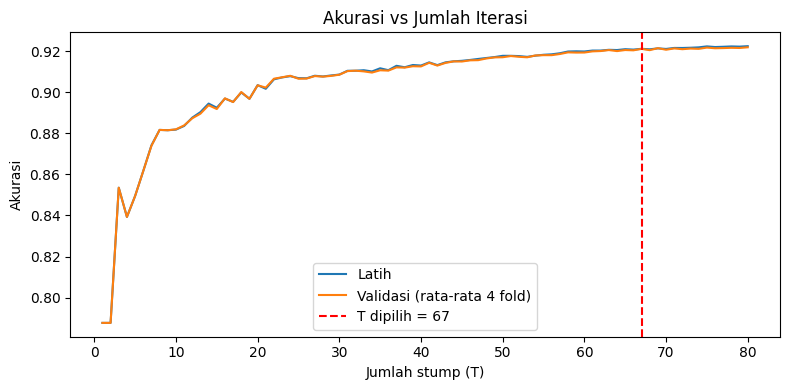

In [ ]:
import matplotlib.pyplot as plt

T_MAX = 80

def latih_model(x_tr, y_tr, T):
    w = np.full(len(y_tr), 1 / len(y_tr))
    model = []
    for t in range(1, T + 1):
        stump = cari_stump_terbaik(x_tr, y_tr, w)
        eps = max(stump["eps"], EPS_MIN)
        alpha = 0.5 * np.log((1 - eps) / eps)
        h = tebak_stump(x_tr, stump)
        w = w * np.exp(-alpha * y_tr * h)
        w = w / w.sum()
        stump["alpha"] = alpha
        model.append(stump)
    return model


def akurasi_per_T(model, x_uji, y_uji):
    """Akurasi kalau hanya 1 stump dipakai, lalu 2 stump, dst sampai semua."""
    H = np.zeros(len(x_uji))
    hasil = []
    for s in model:
        H += s["alpha"] * tebak_stump(x_uji, s)
        hasil.append((np.where(H > 0, 1, -1) == y_uji).mean())
    return np.array(hasil)


fold = train["fold"].to_numpy()
kurva_val, kurva_latih = [], []
for k in sorted(set(fold)):
    is_val = fold == k
    model_k = latih_model(x[~is_val], y[~is_val], T_MAX)      # latih sampai T_MAX sekali saja
    kurva_val.append(akurasi_per_T(model_k, x[is_val], y[is_val]))
    kurva_latih.append(akurasi_per_T(model_k, x[~is_val], y[~is_val]))
    print(f"fold {k} selesai")

acc_val = np.mean(kurva_val, axis=0)
acc_latih = np.mean(kurva_latih, axis=0)

# T terbaik = T terkecil yang akurasinya sudah mendekati yang tertinggi (selisih <= 0,1 poin)
T_terbaik = int(np.argmax(acc_val >= acc_val.max() - 0.001)) + 1
print(f"Akurasi validasi tertinggi: {acc_val.max():.2%} (T = {int(np.argmax(acc_val)) + 1})")
print(f"T yang dipilih (terkecil yang sudah mendekati): {T_terbaik} | akurasi validasi {acc_val[T_terbaik - 1]:.2%}")

plt.figure(figsize=(8, 4))
plt.plot(range(1, T_MAX + 1), acc_latih, label="Latih")
plt.plot(range(1, T_MAX + 1), acc_val, label="Validasi (rata-rata 4 fold)")
plt.axvline(T_terbaik, color="red", linestyle="--", label=f"T dipilih = {T_terbaik}")
plt.xlabel("Jumlah stump (T)")
plt.ylabel("Akurasi")
plt.title("Akurasi vs Jumlah Iterasi")
plt.legend()
plt.tight_layout()
plt.show()

# Cross Validation

## Cross validation 4 fold
Data train sudah punya nomor fold 1 sampai 4 (kolom `fold`). Untuk tiap fold:
- Data fold itu **disisihkan** sebagai validasi (tidak ikut belajar).
- Data sisanya dipakai melatih AdaBoost, langkahnya sama dengan modelling.
- Model diuji ke data validasi.

Data test **tidak ikut**.

fold 1 selesai | akurasi validasi 0.9206
fold 2 selesai | akurasi validasi 0.9230
fold 3 selesai | akurasi validasi 0.9195
fold 4 selesai | akurasi validasi 0.9212


,n latih,n validasi,Akurasi Latih,Akurasi Validasi,Presisi,Recall,F1
Fold,,,,,,,
1,62342,20781,0.9216,0.9206,0.9185,0.8942,0.9062
2,62342,20781,0.9206,0.9230,0.9216,0.9009,0.9112
3,62342,20781,0.9221,0.9195,0.9158,0.8967,0.9062
4,62343,20780,0.9201,0.9212,0.9169,0.8993,0.9080


Ringkasan 4-fold CV (T = 67 stump)


,Rata-rata,Std
Akurasi Latih,0.9211,0.0009
Akurasi Validasi,0.9211,0.0014
Presisi,0.9182,0.0025
Recall,0.8978,0.0030
F1,0.9079,0.0023


Selisih akurasi latih - validasi = 0.0000 -> tidak overfitting


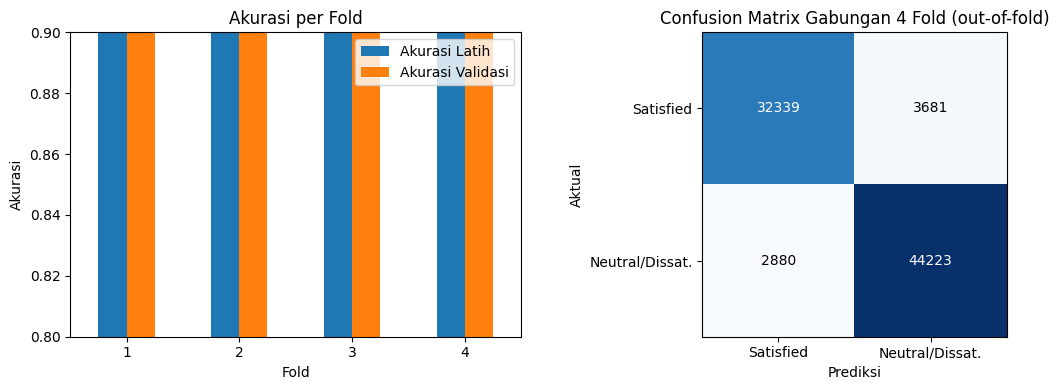

In [ ]:
def hitung_metrik(y_asli, y_pred):
  """Metrik dengan kelas positif = satisfied (+1)."""
  return {
    "Akurasi":   accuracy_score(y_asli, y_pred),
    "Presisi":   precision_score(y_asli, y_pred, pos_label=1),
    "Recall":    recall_score(y_asli, y_pred, pos_label=1),
    "F1":        f1_score(y_asli, y_pred, pos_label=1),
  }

fold = train["fold"].to_numpy()
baris_cv, y_oof, pred_oof = [], np.zeros(len(y), dtype=int), np.zeros(len(y), dtype=int)

for k in sorted(set(fold)):
  is_val = fold == k
  model_k = latih_model(x[~is_val], y[~is_val], T)          # latih di 3 fold lain
  _, pred_val = prediksi(x[is_val], model_k)                # uji di fold k
  _, pred_tr  = prediksi(x[~is_val], model_k)

  m = hitung_metrik(y[is_val], pred_val)
  m["Akurasi Latih"] = accuracy_score(y[~is_val], pred_tr)
  m["Fold"], m["n latih"], m["n validasi"] = k, int((~is_val).sum()), int(is_val.sum())
  baris_cv.append(m)

  y_oof[is_val], pred_oof[is_val] = y[is_val], pred_val
  print(f"fold {k} selesai | akurasi validasi {m['Akurasi']:.4f}")

hasil_cv = pd.DataFrame(baris_cv).set_index("Fold")[
  ["n latih", "n validasi", "Akurasi Latih", "Akurasi", "Presisi", "Recall", "F1"]]
hasil_cv = hasil_cv.rename(columns={"Akurasi": "Akurasi Validasi"})
display(hasil_cv.round(4))

ringkas = hasil_cv[["Akurasi Latih", "Akurasi Validasi", "Presisi", "Recall", "F1"]].agg(["mean", "std"]).T
ringkas.columns = ["Rata-rata", "Std"]
print(f"Ringkasan {JUMLAH_FOLD}-fold CV (T = {T} stump)")
display(ringkas.round(4))

selisih = hasil_cv["Akurasi Latih"].mean() - hasil_cv["Akurasi Validasi"].mean()
print(f"Selisih akurasi latih - validasi = {selisih:.4f} -> " + ("tidak overfitting" if selisih < 0.01 else "ada indikasi overfitting"))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
hasil_cv[["Akurasi Latih", "Akurasi Validasi"]].plot(kind="bar", ax=ax[0], rot=0)
ax[0].set_ylim(0.85, 0.95); ax[0].set_title("Akurasi per Fold"); ax[0].set_ylabel("Akurasi")
cm_oof = confusion_matrix(y_oof, pred_oof, labels=[1, -1])
im = ax[1].imshow(cm_oof, cmap="Blues")
ax[1].set_xticks([0, 1], ["Satisfied", "Neutral/Dissat."]); ax[1].set_yticks([0, 1], ["Satisfied", "Neutral/Dissat."])
ax[1].set_xlabel("Prediksi"); ax[1].set_ylabel("Aktual"); ax[1].set_title("Confusion Matrix Gabungan 4 Fold (out-of-fold)")
for i in range(2):
  for j in range(2):
    ax[1].text(j, i, f"{cm_oof[i, j]}", ha="center", va="center",
        color="white" if cm_oof[i, j] > cm_oof.max() / 2 else "black")
plt.tight_layout(); plt.show()

# Evaluasi

Data test: 20781 baris | Fitur: ['Online_boarding', 'Class', 'Type_of_Travel', 'Inflight_entertainment', 'Seat_comfort', 'On-board_service', 'Leg_room_service', 'Cleanliness', 'Flight_Distance', 'Inflight_wifi_service', 'Baggage_handling', 'Inflight_service', 'Checkin_service', 'Food_and_drink', 'Customer_Type', 'Ease_of_Online_booking', 'Age']

                           precision    recall  f1-score   support

Neutral/Dissatisfied (-1)     0.9258    0.9347    0.9302     11776
           Satisfied (+1)     0.9135    0.9021    0.9077      9005

                 accuracy                         0.9206     20781
                macro avg     0.9197    0.9184    0.9190     20781
             weighted avg     0.9205    0.9206    0.9205     20781



,Train,CV 4-fold (validasi),Test
Akurasi,0.9216,0.9211,0.9206
Presisi,0.9185,0.9182,0.9135
Recall,0.8988,0.8978,0.9021
F1,0.9086,0.9079,0.9077


ROC-AUC test (skor H(x)): 0.9734
Selisih akurasi CV vs test = 0.0005
Baseline (selalu tebak kelas mayoritas): 56.67% | 1 stump: 78.80% | 67 stump: 92.06%


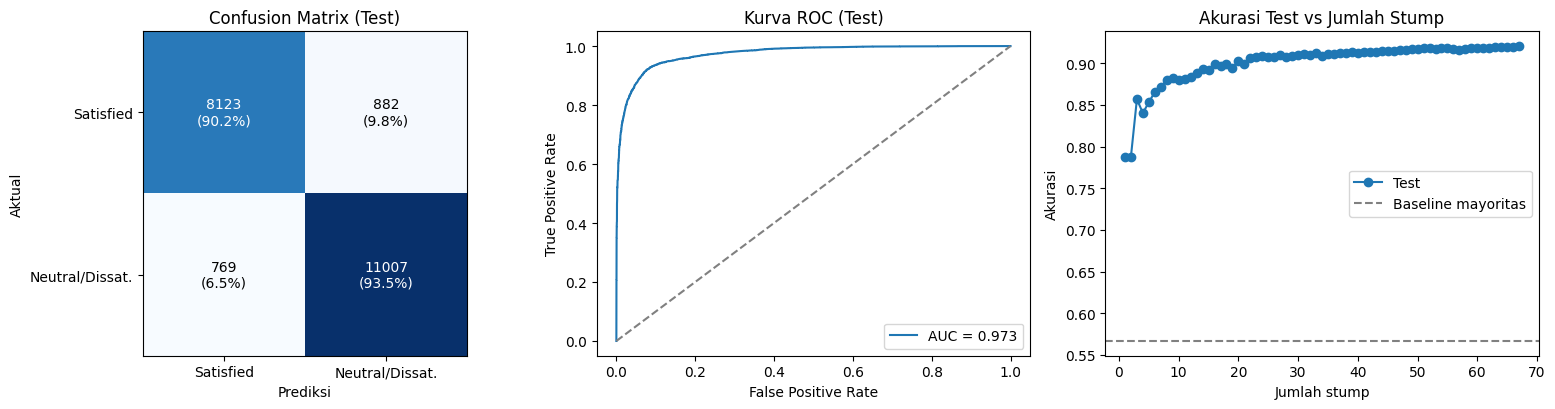

In [ ]:
test = pd.read_csv("test.csv")
x_test = test[fitur].to_numpy()
y_test = test["y"].to_numpy()

model_final = latih_model(x, y, T)                 # seluruh data train
H_test, pred_test = prediksi(x_test, model_final)
_, pred_train = prediksi(x, model_final)

print(f"Data test: {len(y_test)} baris | Fitur: {fitur}\n")
print(classification_report(y_test, pred_test, target_names=["Neutral/Dissatisfied (-1)", "Satisfied (+1)"], digits=4))

metrik_test = hitung_metrik(y_test, pred_test)
auc = roc_auc_score(y_test, H_test)

perbandingan = pd.DataFrame({
  "Train": hitung_metrik(y, pred_train),
  f"CV {JUMLAH_FOLD}-fold (validasi)": hasil_cv[["Akurasi Validasi", "Presisi", "Recall", "F1"]].mean().set_axis(["Akurasi", "Presisi", "Recall", "F1"]).to_dict(),
  "Test": metrik_test,
})
display(perbandingan.round(4))
print(f"ROC-AUC test (skor H(x)): {auc:.4f}")
print(f"Selisih akurasi CV vs test = {abs(perbandingan.loc['Akurasi', f'CV {JUMLAH_FOLD}-fold (validasi)'] - metrik_test['Akurasi']):.4f}")

# Pembanding: tebak kelas mayoritas, dan 1 stump saja
baseline = (y_test == pd.Series(y).mode()[0]).mean()
acc_T = akurasi_per_T(model_final, x_test, y_test)
print(f"Baseline (selalu tebak kelas mayoritas): {baseline:.2%} | 1 stump: {acc_T[0]:.2%} | {T} stump: {acc_T[-1]:.2%}")

cm = confusion_matrix(y_test, pred_test, labels=[1, -1])
fpr, tpr, _ = roc_curve(y_test, H_test)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
ax[0].imshow(cm, cmap="Blues")
nama = ["Satisfied", "Neutral/Dissat."]
ax[0].set_xticks([0, 1], nama); ax[0].set_yticks([0, 1], nama)
ax[0].set_xlabel("Prediksi"); ax[0].set_ylabel("Aktual"); ax[0].set_title("Confusion Matrix (Test)")
for i in range(2):
  for j in range(2):
    ax[0].text(j, i, f"{cm[i, j]}\n({cm[i, j] / cm[i].sum():.1%})", ha="center", va="center",
      color="white" if cm[i, j] > cm.max() / 2 else "black")

ax[1].plot(fpr, tpr, label=f"AUC = {auc:.3f}"); ax[1].plot([0, 1], [0, 1], "--", color="gray")
ax[1].set_xlabel("False Positive Rate"); ax[1].set_ylabel("True Positive Rate"); ax[1].set_title("Kurva ROC (Test)"); ax[1].legend()

ax[2].plot(range(1, T + 1), acc_T, marker="o", label="Test")
ax[2].axhline(baseline, color="gray", linestyle="--", label="Baseline mayoritas")
ax[2].set_xlabel("Jumlah stump"); ax[2].set_ylabel("Akurasi"); ax[2].set_title("Akurasi Test vs Jumlah Stump"); ax[2].legend()
plt.tight_layout(); plt.show()

In [ ]:
konfigurasi = [(5, 12), (17, 12), (17, 24), (17, 67)]   # (jumlah fitur, T)

T_maks = {}
for n, T_k in konfigurasi:
    T_maks[n] = max(T_maks.get(n, 0), T_k)

fold = train["fold"].to_numpy()
y_test = test["y"].to_numpy()
baris = []

for n, T_max in T_maks.items():
    kolom = fitur[:n]
    x_tr, x_te = train[kolom].to_numpy(), test[kolom].to_numpy()

    model_full = latih_model(x_tr, y, T_max)
    model_fold = {k: latih_model(x_tr[fold != k], y[fold != k], T_max) for k in sorted(set(fold))}
    print(f"{n} fitur selesai dilatih")

    for n2, T_k in konfigurasi:
        if n2 != n:
            continue
        acc_cv = []
        for k, m in model_fold.items():
            is_val = fold == k
            _, p = prediksi(x_tr[is_val], m[:T_k])
            acc_cv.append((p == y[is_val]).mean())

        _, p_tr = prediksi(x_tr, model_full[:T_k])
        H_te, p_te = prediksi(x_te, model_full[:T_k])
        mt = hitung_metrik(y_test, p_te)
        baris.append({
            "Fitur": n, "T": T_k,
            "Akurasi Train": (p_tr == y).mean(),
            "Akurasi CV": np.mean(acc_cv), "Std CV": np.std(acc_cv, ddof=1),
            "Akurasi Test": mt["Akurasi"], "Presisi Test": mt["Presisi"],
            "Recall Test": mt["Recall"], "F1 Test": mt["F1"],
            "AUC Test": roc_auc_score(y_test, H_te),
        })

perbandingan_konfig = pd.DataFrame(baris)
perbandingan_konfig.round(4)

5 fitur selesai dilatih
17 fitur selesai dilatih


,Fitur,T,Akurasi Train,Akurasi CV,Std CV,Akurasi Test,Presisi Test,Recall Test,F1 Test,AUC Test
0,5,12,0.8561,0.8554,0.0026,0.8581,0.8226,0.8575,0.8397,0.9273
1,17,12,0.8842,0.8873,0.0038,0.8839,0.8696,0.8612,0.8654,0.9520
2,17,24,0.9093,0.9080,0.0033,0.9084,0.9097,0.8756,0.8923,0.9648
3,17,67,0.9216,0.9211,0.0014,0.9206,0.9135,0.9021,0.9077,0.9734


In [ ]:
hasil_cv.round(6).to_csv("hasil_cv.csv")
ringkas.round(6).to_csv("ringkasan_cv.csv")
perbandingan_konfig.round(6).to_csv("perbandingan_konfig.csv", index=False)
pd.DataFrame({"T": np.arange(1, len(acc_val) + 1),
              "Latih": acc_latih, "Validasi": acc_val}).to_csv("kurva_T.csv", index=False)
print("Semua file tersimpan")

Semua file tersimpan
